In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
import math

In [ ]:
# Create *known* parameters
weight  = 0.8
bias = 0.2

# Create
start = 0
end = 1
step = 0.02
X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias
X[:10], y[:10]



(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.2000],
         [0.2160],
         [0.2320],
         [0.2480],
         [0.2640],
         [0.2800],
         [0.2960],
         [0.3120],
         [0.3280],
         [0.3440]]))

In [ ]:
# min = 0
# max = 100
# step = 10
# array = np.arange(min, max, step)
# print(array + 10)



In [ ]:
def plot_predictions(train_data,
                     train_labels,
                     test_data,
                     test_labels,
                     predictions=None):
  """
  Plots training data, test data and compares predictions.
  """
  plt.figure(figsize=(10, 7))

  # Plot training data in blue
  plt.scatter(train_data, train_labels, c="b", s=4, label="Training data")

  # Plot test data in green
  plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data")

  if predictions is not None:
    # Plot the predictions in red (predictions were made on the test data)
    plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")

  # Show the legend
  plt.legend(prop={"size": 14});

# Machine learning is a game of two parts:

Turn your data, whatever it is, into numbers (a representation).
Pick or build a model to learn the representation as best as possible.
Sometimes one and two can be done at the same time.

But what if you don't have data?
Well, that's where we're at now.

No data.

But we can create some.
Let's create our data as a straight line.

We'll use linear regression to create the data with known parameters (things that can be learned by a model) and then we'll use PyTorch to see if we can build model to estimate these parameters using gradient descent.

Don't worry if the terms above don't mean much now, we'll see them in action and I'll put extra resources below where you can learn more.

https://en.wikipedia.org/wiki/Gradient_descent

# Split data into training and test sets

But before we build a model we need to split it up.

One of most important steps in a machine learning project is creating a training and test set (and when required, a validation set).


- Split	Purpose	Amount of total data	How often is it used?
Training set	The model learns from this data (like the course materials you study during the semester).	~60-80%	Always

- Validation set	The model gets tuned on this data (like the practice exam you take before the final exam).	~10-20%	Often but not always
Testing set	The model gets evaluated on this data to test what it has learned (like the final exam you take at the end of the semester).	~10-20%	Always
For now, we'll just use a training and test set, this means we'll have a dataset for our model to learn on as well as be evaluated on.

We can create them by splitting our X and y tensors.



In [ ]:
len(X), len(y)

(50, 50)

In [ ]:
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
x_test, y_test  = X[train_split:], y[train_split:]
len(X_train), len(y_train), len(x_test), len(y_test)


(40, 40, 10, 10)

<function matplotlib.pyplot.legend(*args, **kwargs) -> 'Legend'>

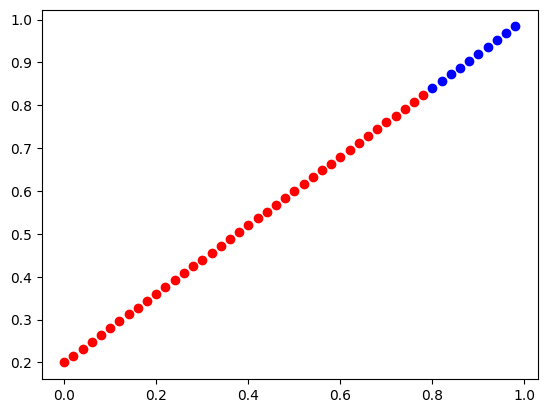

In [ ]:
import matplotlib.pyplot as plt
plt.scatter(X_train, y_train, c="r", label = "Training data")
plt.scatter(x_test, y_test, c="b", label = "Testing data")
plt.legend

In [ ]:
# from sklearn.model_selection import train_test_split
# from sklearn.linear_model import LinearRegression
# lm = LinearRegression()
# lm.fit(X_train, y_train)
# test_x = lm.predict(x_test)
# test_x

class LinearRegressionModel(nn.Module):
  # Almost everything in pytorch inherits from nn.module
  def __init__(self):
    super().__init__()
    self.weights = nn.Parameter(torch.randn(1, requires_grad=True, dtype= torch.float))
    self.bias = nn.Parameter(torch.randn(1, requires_grad =True, dtype=torch.float))

  def forward(self, x:torch.Tensor) -> torch.Tensor:
    return self.weights * x + self.bias



Recommendation: Watch Backpropogation and gradient descent, pure fun physics. 3blue1brown.

Subclass nn.Module => contains all the building blocks for neural networks
Initialise model parameter => used in varios competations.
requires_grad = true => Pytorch will track the gradient function, the vector partial derivative.

def(forward) => any subclass of nn.module needs to override forward(). This defines  the computation model

In [ ]:
# Pytorch model
torch.manual_seed(42)
# Create an instance of model (this is a subclass of nn.module)
model_0 = LinearRegressionModel()
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

torch.nn - contains all of the builfing for computational graphs
torch.nn.Paramter - what parameters should our model try and learn
Module, the base network modules

In [ ]:
# List named parameters
weight, bias

(0.8, 0.2)

In [ ]:
model_0.state_dict()
# This is the prediction of the model. We are going to feed more data until it get's the weight and bias correct.

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [ ]:
# To check models predicitive power, let's see how well it predicts y_test given x_test



# WOhooo, perfect, it can predict it perfectly. Let's do the same using our class and pytorch.

In [ ]:
# Making predictions with our model
with torch.inference_mode():
  y_preds = model_0(x_test)
y_preds

tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

In [ ]:
y_test

tensor([[0.8400],
        [0.8560],
        [0.8720],
        [0.8880],
        [0.9040],
        [0.9200],
        [0.9360],
        [0.9520],
        [0.9680],
        [0.9840]])

## Let's functionize the plot_predictions code for later use.

In [ ]:
def plot_predictions(train_data, train_labels, test_data, test_labels, predictions=None):
  """
  Plots training data, test data and compares predictions.
  """
  plt.figure(figsize=(10, 7))

  # Plot training data in blue
  plt.scatter(train_data, train_labels, c="r", s=4, label="Training data")

  # Plot test data in green
  plt.scatter(test_data, test_labels, c="b", s=4, label="Testing data")

  # Are there predictions?
  if predictions is not None:
    # Plot the predictions in red (predictions were made on the test data)
    plt.scatter(test_data, predictions, c="g", s=4, label="Predictions")

  # Show the legend
  plt.legend(prop={"size": 14})
  plt.show()

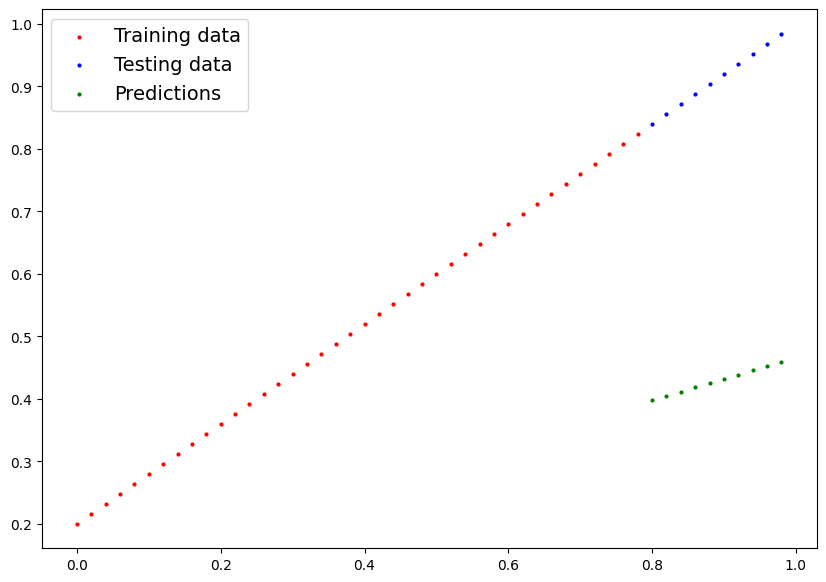

In [ ]:
plot_predictions(train_data=X_train, train_labels=y_train, test_data=x_test, test_labels=y_test, predictions=y_preds)

As we can see, the predictions are no where near reailty, even though the pattern is extremley straight forward.
This is is because they start from unknown or paramater and slowly shift to known parameters through checking the consistancy of the results.
There is a loss function to track the error. The optimizer, takes the loss function into consideration and tweaks the prediction till we have a perfect prediction.


In [ ]:
list(model_0.parameters())


[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

 We need a training loop and a testing loop. By lowering the loss function every time, we would get the red dots near the green dots.

In [ ]:
# Setting up a loss function:
loss_fn = nn.L1Loss()

# Set up an optimizer
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01)
# lr = learning rate, super important. Can be seen as arange/ how big a step.


# Let's write a training loop!

In [ ]:
# An epoch is the one loop through the data
torch.manual_seed(42)
epochs = 250

epoch_count = []
loss_values = []
test_loss_values = []

#0. Loop thorugh the data
for epoch in range(epochs):

  # Set the model to training mode:
  model_0.train()
  # => sets all param that require gradeint to False

  # 1. Forward pass
  y_pred = model_0(X_train)

  # 2. Calculate the loss
  loss = loss_fn(y_pred, y_train)
  # print(loss)


  # 3. Optimizer 0 grad
  optimizer.zero_grad()

  # 4. Perform backpropagation on the loss with respect to param of the model
  loss.backward()

  # 5. Step the optimizer (perform gradient descent)
  optimizer.step()
  # by default how the optimiser changes will accumulate through the loop so.. we have to 0 them above in step 3

  model_0.eval()
  # print(model_0.state_dict() )
  with torch.inference_mode():
    test_pred = model_0(x_test)
    test_loss = loss_fn(test_pred, y_test)
    # print(f"Epoch: {epoch} | test_loss: {test_loss}")

  # Append to loss lists
  epoch_count.append(epoch)
  loss_values.append(loss.detach().numpy())
  test_loss_values.append(test_loss.detach().numpy())

In [ ]:
torch.manual_seed(42)
epochs = 250
for epoch in range(epochs):
  y_pred = model_0(X_train)
  loss = loss_fn(y_pred, y_train)
  print(loss)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model_0.eval()
  print(model_0.state_dict() )

  # Testing
  model_0.eval()
  with torch.inference_mode():
    test_pred = model_0(x_test)
    test_loss = loss_fn(test_pred, y_test)
    print(f"Epoch: {epoch} | test_loss: {test_loss}")

# Understanding what is happening.
# Epoch =  number of times the data is passed through the model

# Y-pred = model_0(X_train) => Pass the data through the model, this will perform the forward() method located within the model object.

# Loss function => calculate the loss value

# Zero the gradients = > quite technical, but they pretty much accumulate every epoch, we need a fresh start for the next epoch

# Perform Backpropagation => take the gradeients of the loss function, computes the grad of every para with requires_grad = True.

tensor(0.0089, grad_fn=<MeanBackward0>)
OrderedDict({'weights': tensor([0.7951]), 'bias': tensor([0.1993])})
Epoch: 0 | test_loss: 0.005093771032989025
tensor(0.0026, grad_fn=<MeanBackward0>)
OrderedDict({'weights': tensor([0.7990]), 'bias': tensor([0.2093])})
Epoch: 1 | test_loss: 0.008377224206924438
tensor(0.0089, grad_fn=<MeanBackward0>)
OrderedDict({'weights': tensor([0.7951]), 'bias': tensor([0.1993])})
Epoch: 2 | test_loss: 0.005093771032989025
tensor(0.0026, grad_fn=<MeanBackward0>)
OrderedDict({'weights': tensor([0.7990]), 'bias': tensor([0.2093])})
Epoch: 3 | test_loss: 0.008377224206924438
tensor(0.0089, grad_fn=<MeanBackward0>)
OrderedDict({'weights': tensor([0.7951]), 'bias': tensor([0.1993])})
Epoch: 4 | test_loss: 0.005093771032989025
tensor(0.0026, grad_fn=<MeanBackward0>)
OrderedDict({'weights': tensor([0.7990]), 'bias': tensor([0.2093])})
Epoch: 5 | test_loss: 0.008377224206924438
tensor(0.0089, grad_fn=<MeanBackward0>)
OrderedDict({'weights': tensor([0.7951]), 'bias'

In [ ]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.7990])), ('bias', tensor([0.2093]))])

In [ ]:
weight, bias


(0.8, 0.2)

In [ ]:
with torch.inference_mode():
  y_preds_new = model_0(x_test)
  y_preds_new

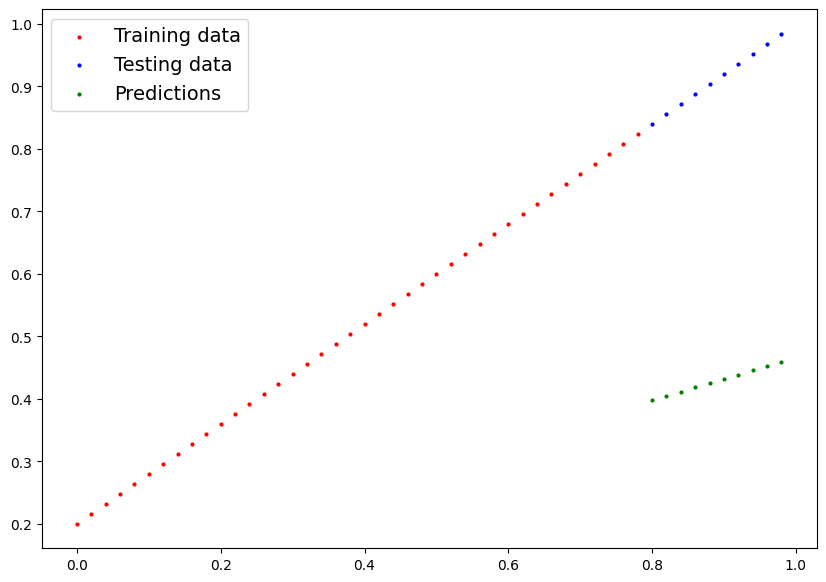

In [ ]:
plot_predictions(train_data=X_train, train_labels=y_train, test_data=x_test, test_labels=y_test, predictions=y_preds)

#That's an awful prediction.
But remember, the values (weights and biases) are completletely random.

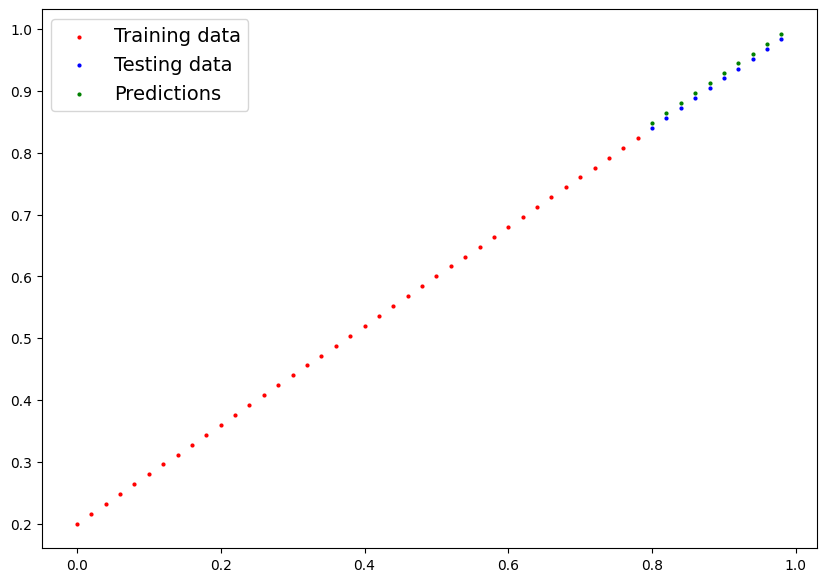

In [ ]:
plot_predictions(train_data=X_train, train_labels=y_train, test_data=x_test, test_labels=y_test, predictions=y_preds_new)

# That's way better.
Behind the scenes, using algorithms like Gradient Descent and back propagation, the training loops adjusts its weight and biases until we have a somewhat accurate prediction, like in the image above.

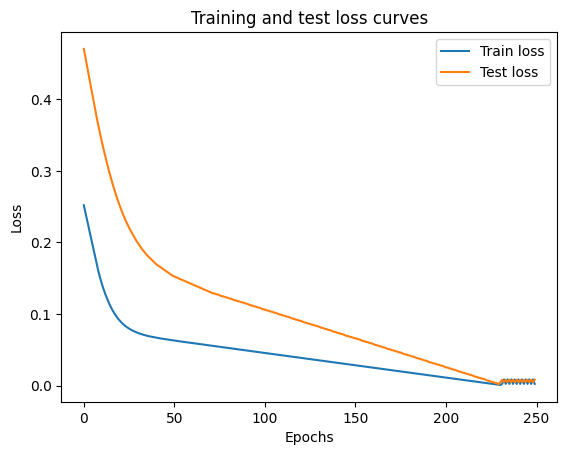

In [ ]:
# Plot the loss curves
plt.plot(epoch_count, loss_values, label="Train loss")
plt.plot(epoch_count, test_loss_values, label="Test loss")
plt.title("Training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend();

# A loss curve
This helps us moniter, especially in larger and more complex models, the behavior and accuracy of the model. There are countless ways to evaluate, and other methods will be discovered later in the series.

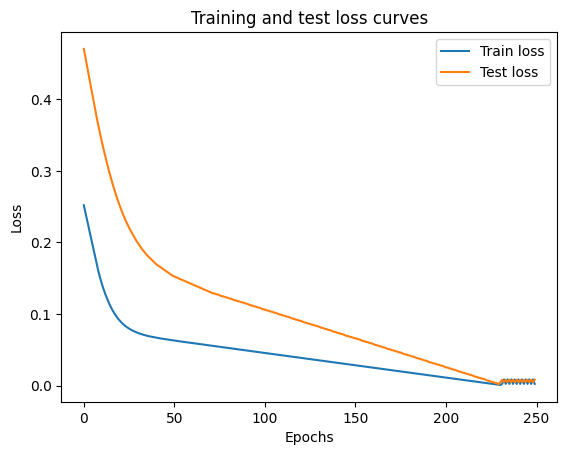

In [ ]:
# Plot the loss curves
plt.plot(epoch_count, loss_values, label="Train loss")
plt.plot(epoch_count, test_loss_values, label="Test loss")
plt.title("Training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend();

# Saving a model a in Pytorch.

In [ ]:
# torch.save() => saves in python pickle

 1. torch.save() => saves in python pickle
 2. torch.load() => allows you to load a saved Pytorch object
 3. torch.nn.Module.load_state_dict()

In [ ]:
from pathlib import Path

# 1. Create models dictionary
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# 2. Create model save path
MODEL_NAME = "01_pytorch_workflow_model.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# 3. Save the model state dict
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj=model_0.state_dict(), f=MODEL_SAVE_PATH)


Saving model to: models/01_pytorch_workflow_model.pth


In [ ]:
torch.load(MODEL_SAVE_PATH)


OrderedDict([('weights', tensor([0.7990])), ('bias', tensor([0.2093]))])

In [ ]:
# But this way, we have saved the models state_dict but not the entire model itself.
loaded_model_0 = LinearRegressionModel()
loaded_model_0.state_dict()
# As we can see, it is still using the random values.
loaded_model_0.load_state_dict(torch.load(MODEL_SAVE_PATH))
loaded_model_0.state_dict()

OrderedDict([('weights', tensor([0.7990])), ('bias', tensor([0.2093]))])

In [ ]:
# Make some predictions
loaded_model_0.eval()
with torch.inference_mode():
  loaded_model_preds = loaded_model_0(x_test)
loaded_model_preds

tensor([[0.8485],
        [0.8645],
        [0.8804],
        [0.8964],
        [0.9124],
        [0.9284],
        [0.9443],
        [0.9603],
        [0.9763],
        [0.9923]])

In [ ]:
y_preds_new

tensor([[0.8485],
        [0.8645],
        [0.8804],
        [0.8964],
        [0.9124],
        [0.9284],
        [0.9443],
        [0.9603],
        [0.9763],
        [0.9923]])

In [ ]:
# Putting it all together.

Epoch: 0 | Loss: 0.25017791986465454 | Test loss: 0.5189762115478516
Epoch: 10 | Loss: 0.15519501268863678 | Test loss: 0.39766672253608704
Epoch: 20 | Loss: 0.11318626254796982 | Test loss: 0.3153371214866638
Epoch: 30 | Loss: 0.0956684872508049 | Test loss: 0.2618848383426666
Epoch: 40 | Loss: 0.08763538300991058 | Test loss: 0.22820448875427246
Epoch: 50 | Loss: 0.08295775204896927 | Test loss: 0.2063898742198944
Epoch: 60 | Loss: 0.07914460450410843 | Test loss: 0.1913021206855774
Epoch: 70 | Loss: 0.07565458863973618 | Test loss: 0.180282324552536
Epoch: 80 | Loss: 0.07216458022594452 | Test loss: 0.16926255822181702
Epoch: 90 | Loss: 0.06870017200708389 | Test loss: 0.15961650013923645
Epoch: 100 | Loss: 0.06526829302310944 | Test loss: 0.15203097462654114
Epoch: 110 | Loss: 0.061835337430238724 | Test loss: 0.1437586098909378
Epoch: 120 | Loss: 0.05839652940630913 | Test loss: 0.13548623025417328
Epoch: 130 | Loss: 0.05496630817651749 | Test loss: 0.12790074944496155
Epoch: 140 

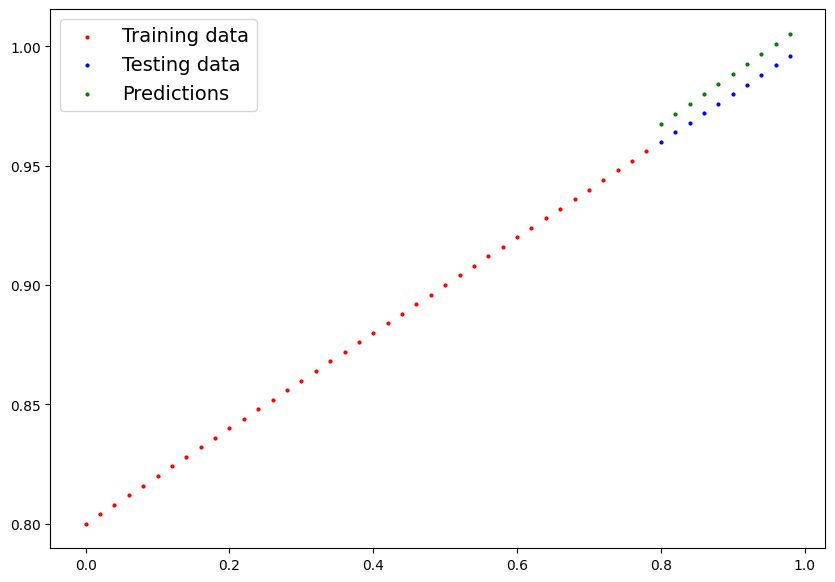

In [ ]:
# Trying to code the whole thing myself:
import torch
import matplotlib.pyplot as plt
from torch import nn
from pathlib import Path
import numpy as np

device = "cuda" if torch.cuda.is_available() else "cpu"
# print(f"{device} is being used." )

bias = 0.8
weight = 0.2

start = 0
end = 1
step = 0.02

X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias

train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
x_test, y_test = X[train_split:], y[train_split:]

# Move data to the target device
X_train = X_train.to(device)
y_train = y_train.to(device)
x_test = x_test.to(device)
y_test = y_test.to(device)


# plt.scatter(X_train.cpu(), y_train.cpu(), c="r", label = "Training data")
# plt.scatter(x_test.cpu(), y_test.cpu(), c="b", label = "Testing data")
# plt.legend()

class LinearRegressionModelV2(nn.Module):
  def __init__(self):
    super().__init__()
    # Use nn.Linear() to create the model parameters.
    self.linear_layer = nn.Linear(in_features=1, out_features=1)

  def forward(self, x:torch.Tensor) -> torch.Tensor:
    return self.linear_layer(x)

torch.manual_seed(42)
model_1 = LinearRegressionModelV2()
# model_1 = model_1.state_dict() # This line caused the error


model_1.to(device)
next(model_1.parameters()).device

# Training part: Things we need : loss function, optimizer, training and testing loop
loss_fn = nn.L1Loss()

# The optimizer:
optimizer = torch.optim.SGD(params=model_1.parameters() , lr=0.01)

epochs = 500
# Training loop:

for epoch in range(epochs):
  model_1.train()
  y_pred = model_1(X_train)

  # 2. Calculate the loss:
  loss = loss_fn(y_pred, y_train)

  # 3. Optimize 0 grad:
  optimizer.zero_grad()

  # 4. perform backpropagation
  loss.backward()

  # 5. optimizer.step()
  optimizer.step()

  # testing
  model_1.eval()
  with torch.inference_mode():
    test_pred = model_1(x_test)
    test_loss = loss_fn(test_pred, y_test)

  if epoch % 10 == 0:
    print(f"Epoch: {epoch} | Loss: {loss} | Test loss: {test_loss}")

print(model_1.state_dict())

with torch.inference_mode():
  y_preds = model_1(x_test)
plot_predictions(
    train_data=X_train.cpu(),
    train_labels=y_train.cpu(),
    test_data=x_test.cpu(),
    test_labels=y_test.cpu(),
    predictions=y_preds.cpu())





In [ ]:
from pathlib import Path

# 1. Create models directory
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# 2. Create model save path
MODEL_NAME = "01_pytorch_workflow_model_1.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# 3. Save the model state dict
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj=model_1.state_dict(), # only saving the state_dict() only saves the models learned parameters
           f=MODEL_SAVE_PATH)

Saving model to: models/01_pytorch_workflow_model_1.pth


In [ ]:
# Loading a pytorch Model

# Instantiate a fresh instance of LinearRegressionModelV2
loaded_model_1 = LinearRegressionModelV2()

# Load model state dict
loaded_model_1.load_state_dict(torch.load(MODEL_SAVE_PATH))

# Put model to target device (if your data is on GPU, model will have to be on GPU to make predictions)
loaded_model_1.to(device)



LinearRegressionModelV2(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)

In [ ]:
next(loaded_model_1.parameters()).device

device(type='cpu')

In [ ]:
loaded_model_1.eval()
with torch.inference_mode():
  loaded_model_1_preds = loaded_model_1(x_test)
loaded_model_1_preds
# Check if the predictions are the same as the previous ones
y_preds == loaded_model_1_preds

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])

In [ ]:
model_0 = nn.Sequential(
    nn.Linear(in_features=2, out_features=5),
    nn.Linear(in_features=5, out_features=1)
).to(device)
# An easier way of doing what we just did. However, when working with more complex models, it is important to know how to work with the steps yourself.

model_0

Sequential(
  (0): Linear(in_features=2, out_features=5, bias=True)
  (1): Linear(in_features=5, out_features=1, bias=True)
)

# With that, we have just trained our first ML model, a simple predictor that can accuratley (with 99% accuracy) prediction the next dot in a linear function.

The continuation for this series (02_pytorch) lies in the same repository in Github.